# Credit Card Fraud Detection

## Project Overview
- Credit Card Fraud Detection is a Machine Learning project that identifies fraudulent credit card transactions. It analyzes transaction data and uses classification algorithms to distinguish between legitimate and fraudulent transactions.

- The project aims to develop an accurate and reliable model that can help detect suspicious financial transactions.

## Problem Statement

- Credit card fraud is a major challenge in the financial industry. Fraudulent transactions can cause financial losses for customers and financial institutions.

- Traditional fraud detection methods may fail to identify complex transaction patterns. Therefore, a Machine Learning-based system is required to analyze transaction data and classify transactions as legitimate or fraudulent.

## Project Objectives

- Analyze credit card transaction data.
- Identify fraudulent transaction patterns.
- Handle imbalanced datasets.
- Apply multiple Machine Learning algorithms.
- Compare model performance.
- Improve fraud detection using model optimization.
- Develop an interactive fraud detection application using Streamlit.

## Technology Used

- **Programming:** Python
- **Environment:** Jupyter Notebook
- **Libraries:** NumPy, Pandas
- **Visualization:** Matplotlib, Seaborn
- **Machine Learning:** Scikit-learn, XGBoost
- **Imbalanced Data:** SMOTE
- **Model Saving:** Joblib
- **Deployment:** Streamlit
- **Dataset:** Kaggle Credit Card Fraud Detection

### Step 1 – Library Import

#### 1.1 Import Libraries

In [1]:
# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
import sklearn

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


#### 1.2 Load Dataset

In [2]:
# Load Dataset
df = pd.read_csv("../data/creditcard.csv")

# Display First 5 Rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#### 1.3 Dataset Shape

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (284807, 31)


### Step 2 – Data Understanding

#### 2.1 Dataset Overview

In [4]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

#### 2.2 Statistical Summary

In [5]:
# Statistical Summary
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


#### 2.3 Column Names

In [6]:
# Display Column Names
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

#### 2.4 Dataset Size

In [7]:
# Number of Rows and Columns
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 284807
Total Columns: 31


#### 2.5 Data Types

In [8]:
# Check Data Types
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

#### 2.6 Target Analysis

In [9]:
# Target Variable Distribution
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

### Step 3 – Data Cleaning

#### 3.1 Missing Values

In [10]:
# Check Missing Values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

#### 3.2 Duplicate Records

In [11]:
# Check Duplicate Records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 1081


#### 3.3 Remove Duplicates

In [12]:
# Remove Duplicate Records
df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Shape After Removing Duplicates: (283726, 31)


#### 3.4 Verify Missing Values

In [13]:
# Verify Missing Values
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


#### 3.5 Verify Duplicates

In [14]:
# Verify Duplicate Records
print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


#### 3.6 Cleaned Dataset

In [15]:
# Final Dataset Shape
print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (283726, 31)


### Step 4 – Exploratory Data Analysis

#### 4.1 Target Distribution

In [16]:
# Count Transaction Classes
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

#### 4.2 Target Visualization

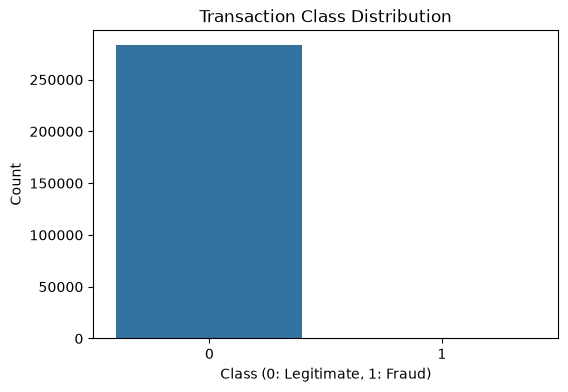

In [17]:
# Visualize Transaction Classes
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Class')

plt.title('Transaction Class Distribution')
plt.xlabel('Class (0: Legitimate, 1: Fraud)')
plt.ylabel('Count')

plt.show()

#### 4.3 Fraud Percentage

In [18]:
# Calculate Class Percentage
class_percentage = df['Class'].value_counts(normalize=True) * 100

print(class_percentage)

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


#### 4.4 Transaction Amount

In [19]:
# Transaction Amount Statistics
df['Amount'].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

#### 4.5 Amount Distribution

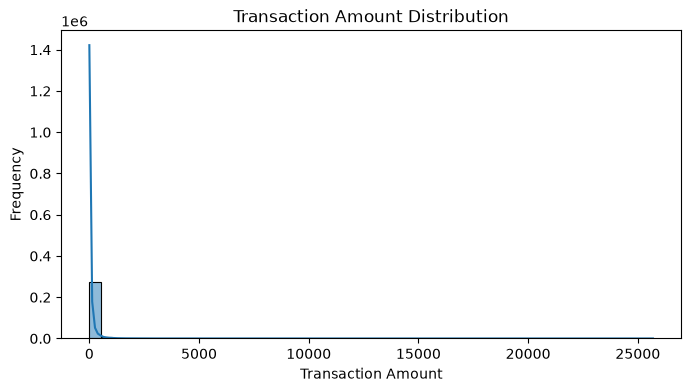

In [20]:
# Transaction Amount Distribution
plt.figure(figsize=(8, 4))

sns.histplot(df['Amount'], bins=50, kde=True)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

#### 4.6 Fraud Amount Analysis

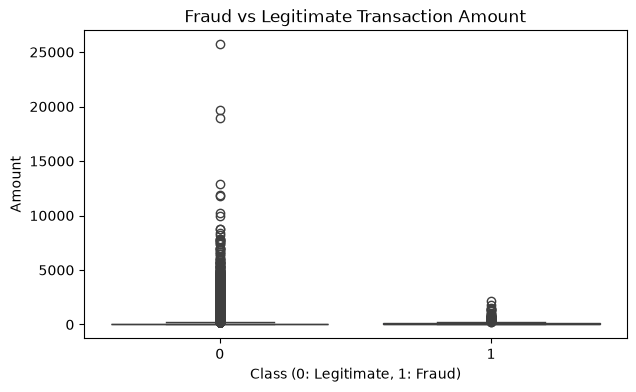

In [21]:
# Compare Transaction Amounts
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x='Class', y='Amount')

plt.title('Fraud vs Legitimate Transaction Amount')
plt.xlabel('Class (0: Legitimate, 1: Fraud)')
plt.ylabel('Amount')

plt.show()

#### 4.7 Correlation Analysis

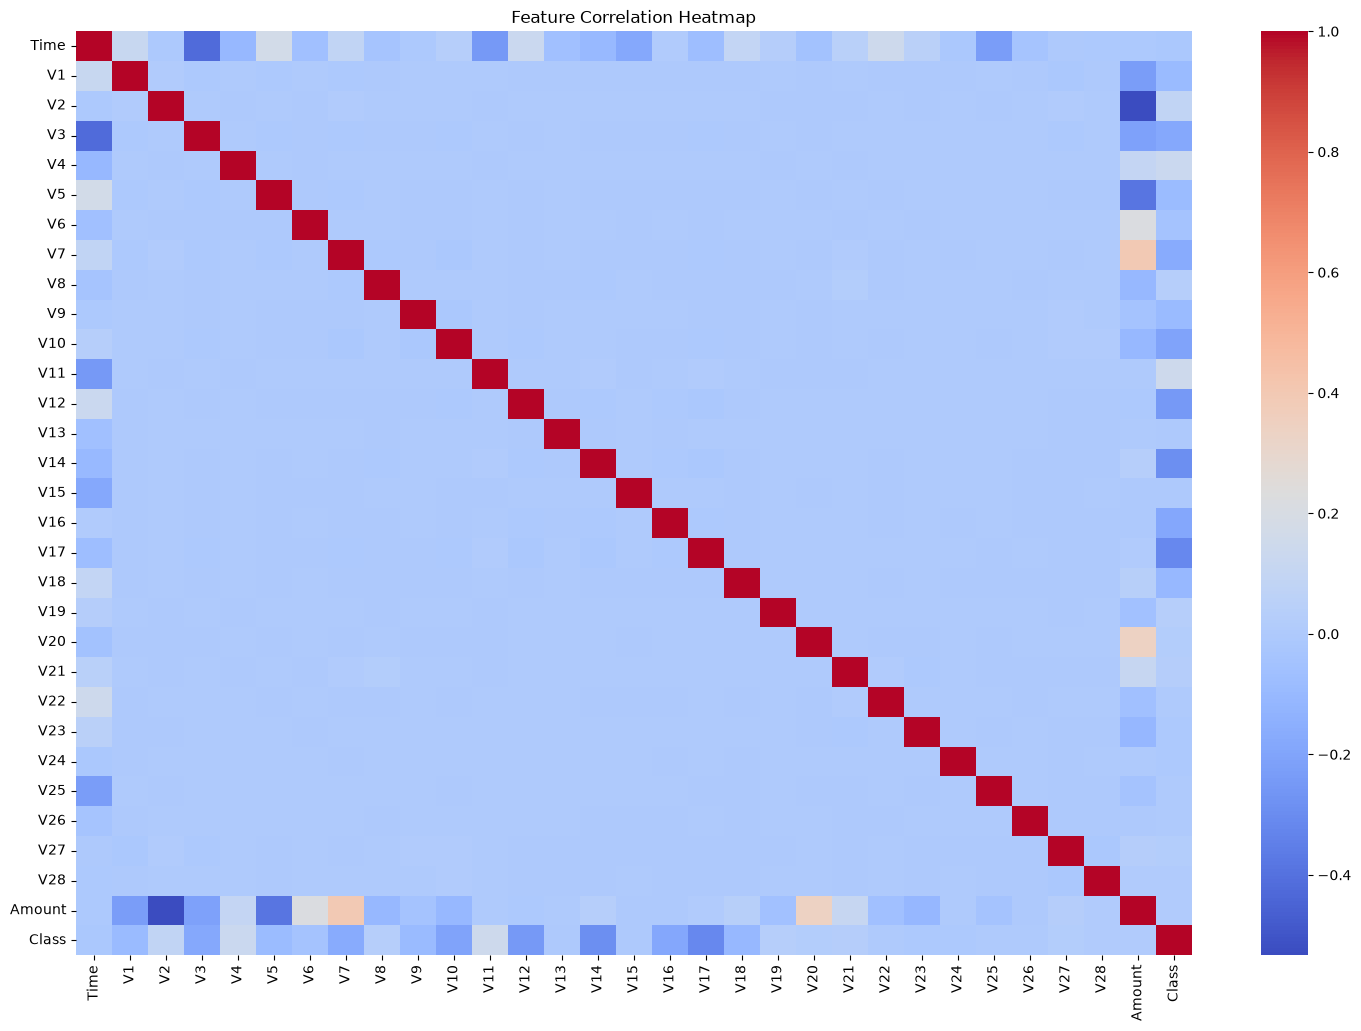

In [22]:
# Correlation Matrix
correlation = df.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(correlation, cmap='coolwarm', annot=False)

plt.title('Feature Correlation Heatmap')

plt.show()

#### 4.8 Class Statistics

In [23]:
# Compare Class Statistics
df.groupby('Class')['Amount'].agg(['count', 'mean', 'median', 'min', 'max'])

,count,mean,median,min,max
Class,,,,,
0,283253,88.413575,22.00,0.0,25691.16
1,473,123.871860,9.82,0.0,2125.87


### Step 5 – Data Preprocessing
- In this step, we will prepare our cleaned dataset for Machine Learning model training.

#### 5.1 Feature Selection

In [24]:
# Separate Features and Target
X = df.drop('Class', axis=1)
y = df['Class']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (283726, 30)
Target Shape: (283726,)


#### 5.2 Numerical Features

In [25]:
# Check Numerical Features
numerical_features = X.select_dtypes(include=np.number).columns

print("Total Numerical Features:", len(numerical_features))
print("\nNumerical Features:")
print(list(numerical_features))

Total Numerical Features: 30

Numerical Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


#### 5.3 Feature Scaling
- We will use StandardScaler to standardize the Time and Amount columns. The PCA transformed V1–V28 features are already scaled/transformed, so we will leave them unchanged.

In [26]:
from sklearn.preprocessing import StandardScaler

# Initialize Scaler
scaler = StandardScaler()

# Scale Selected Features
X_scaled = X.copy()

X_scaled[['Time', 'Amount']] = scaler.fit_transform(
    X_scaled[['Time', 'Amount']]
)

print("Feature Scaling Completed!")
print("Scaled Features Shape:", X_scaled.shape)

Feature Scaling Completed!
Scaled Features Shape: (283726, 30)


#### 5.4 Scaled Data

In [27]:
# Display First Five Rows
X_scaled.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.996823,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244200
1,-1.996823,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342584
2,-1.996802,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.158900
3,-1.996802,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.139886
4,-1.996781,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073813


#### 5.5 Train Test Split
- We will divide the dataset:
    - 80% – Training data
    - 20% – Testing data
- We will use stratification to preserve the fraud-to-legitimate ratio.

In [28]:
from sklearn.model_selection import train_test_split

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (226980, 30)
Testing Features: (56746, 30)
Training Target: (226980,)
Testing Target: (56746,)


#### 5.6 Class Distribution

In [29]:
# Check Training Class Distribution
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Class Distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56651
1       95
Name: count, dtype: int64


### Step 6 – Handling Imbalanced Data

#### 6.1 Class Distribution

In [30]:
# Check Class Distribution
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64


#### 6.2 Apply SMOTE
- SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic examples of the minority class to balance the training dataset.

In [31]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to Training Data Only
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("SMOTE Applied Successfully!")

SMOTE Applied Successfully!


#### 6.3 Balanced Distribution

In [32]:
# Check Balanced Class Distribution
print("After SMOTE:")
print(y_train_smote.value_counts())

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64


#### 6.4 Balanced Dataset Shape

In [33]:
# Check New Dataset Shape
print("Before SMOTE:", X_train.shape)
print("After SMOTE:", X_train_smote.shape)

Before SMOTE: (226980, 30)
After SMOTE: (453204, 30)


#### 6.5 SMOTE Visualization

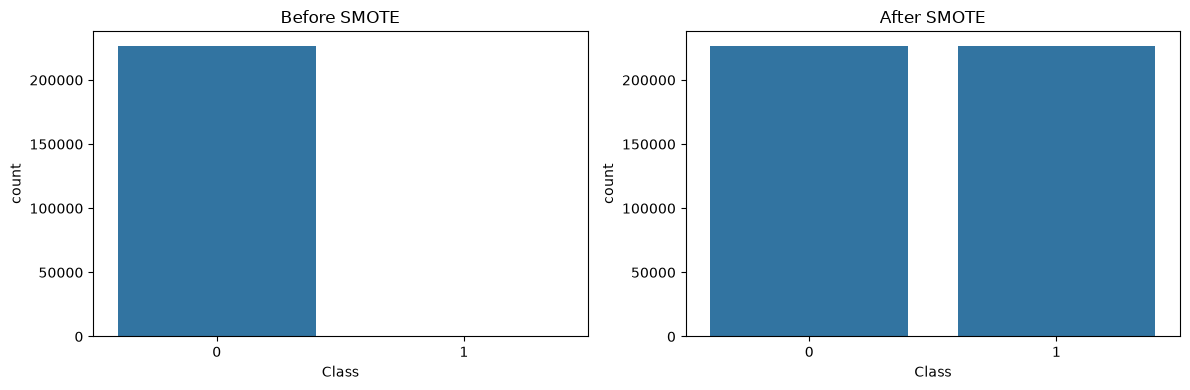

In [34]:
# Compare Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

### Step 7 – Model Building
- Objective: Train five ML algorithms to identify fraudulent credit card transactions.

#### 7.1 Import Models

In [35]:
# Import Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

print("All ML models imported successfully!")

All ML models imported successfully!


#### 7.2 Initialize Models

In [36]:
# Initialize Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

print("Total Models:", len(models))
print("\nModel Names:")

for name in models:
    print(name)

Total Models: 5

Model Names:
Logistic Regression
Decision Tree
Random Forest
KNN
XGBoost


#### 7.3 Train Models
- We will train all five models using our SMOTE-balanced training dataset.

In [37]:
# Train Machine Learning Models

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_smote, y_train_smote)

    trained_models[name] = model

    print(f"{name} Trained Successfully!\n")

print("All Models Training Completed!")

Training Logistic Regression...
Logistic Regression Trained Successfully!

Training Decision Tree...
Decision Tree Trained Successfully!

Training Random Forest...
Random Forest Trained Successfully!

Training KNN...
KNN Trained Successfully!

Training XGBoost...
XGBoost Trained Successfully!

All Models Training Completed!


#### 7.4 Check Models

In [38]:
# Display Trained Models

print("Trained Models:")

for name, model in trained_models.items():
    print(name, ":", type(model).__name__)

Trained Models:
Logistic Regression : LogisticRegression
Decision Tree : DecisionTreeClassifier
Random Forest : RandomForestClassifier
KNN : KNeighborsClassifier
XGBoost : XGBClassifier


### Step 8 – Model Evaluation

#### 8.1 Import Metrics

In [39]:
# Import Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Evaluation Metrics Imported Successfully!")

Evaluation Metrics Imported Successfully!


#### 8.2 Model Predictions

In [40]:
# Generate Predictions

predictions = {}
probabilities = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name} Predictions Completed!")

print("\nAll Predictions Generated Successfully!")

Logistic Regression Predictions Completed!
Decision Tree Predictions Completed!
Random Forest Predictions Completed!
KNN Predictions Completed!
XGBoost Predictions Completed!

All Predictions Generated Successfully!


#### 8.3 Performance Metrics

In [41]:
# Calculate Model Performance

results = []

for name in trained_models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.973725,0.053137,0.873684,0.100181,0.961850
1,Decision Tree,0.997903,0.425000,0.715789,0.533333,0.857083
2,Random Forest,0.999471,0.911392,0.757895,0.827586,0.954320
3,KNN,0.998150,0.469880,0.821053,0.597701,0.909967
4,XGBoost,0.996299,0.289377,0.831579,0.429348,0.976251


#### 8.4 Classification Report

In [42]:
# Detailed Classification Report

for name in trained_models:

    print("\nModel:", name)
    print("-" * 50)

    print(classification_report(
        y_test,
        predictions[name],
        target_names=["Legitimate", "Fraud"]
    ))


Model: Logistic Regression
--------------------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56651
       Fraud       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746


Model: Decision Tree
--------------------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.42      0.72      0.53        95

    accuracy                           1.00     56746
   macro avg       0.71      0.86      0.77     56746
weighted avg       1.00      1.00      1.00     56746


Model: Random Forest
--------------------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud

#### 8.5 Confusion Matrix

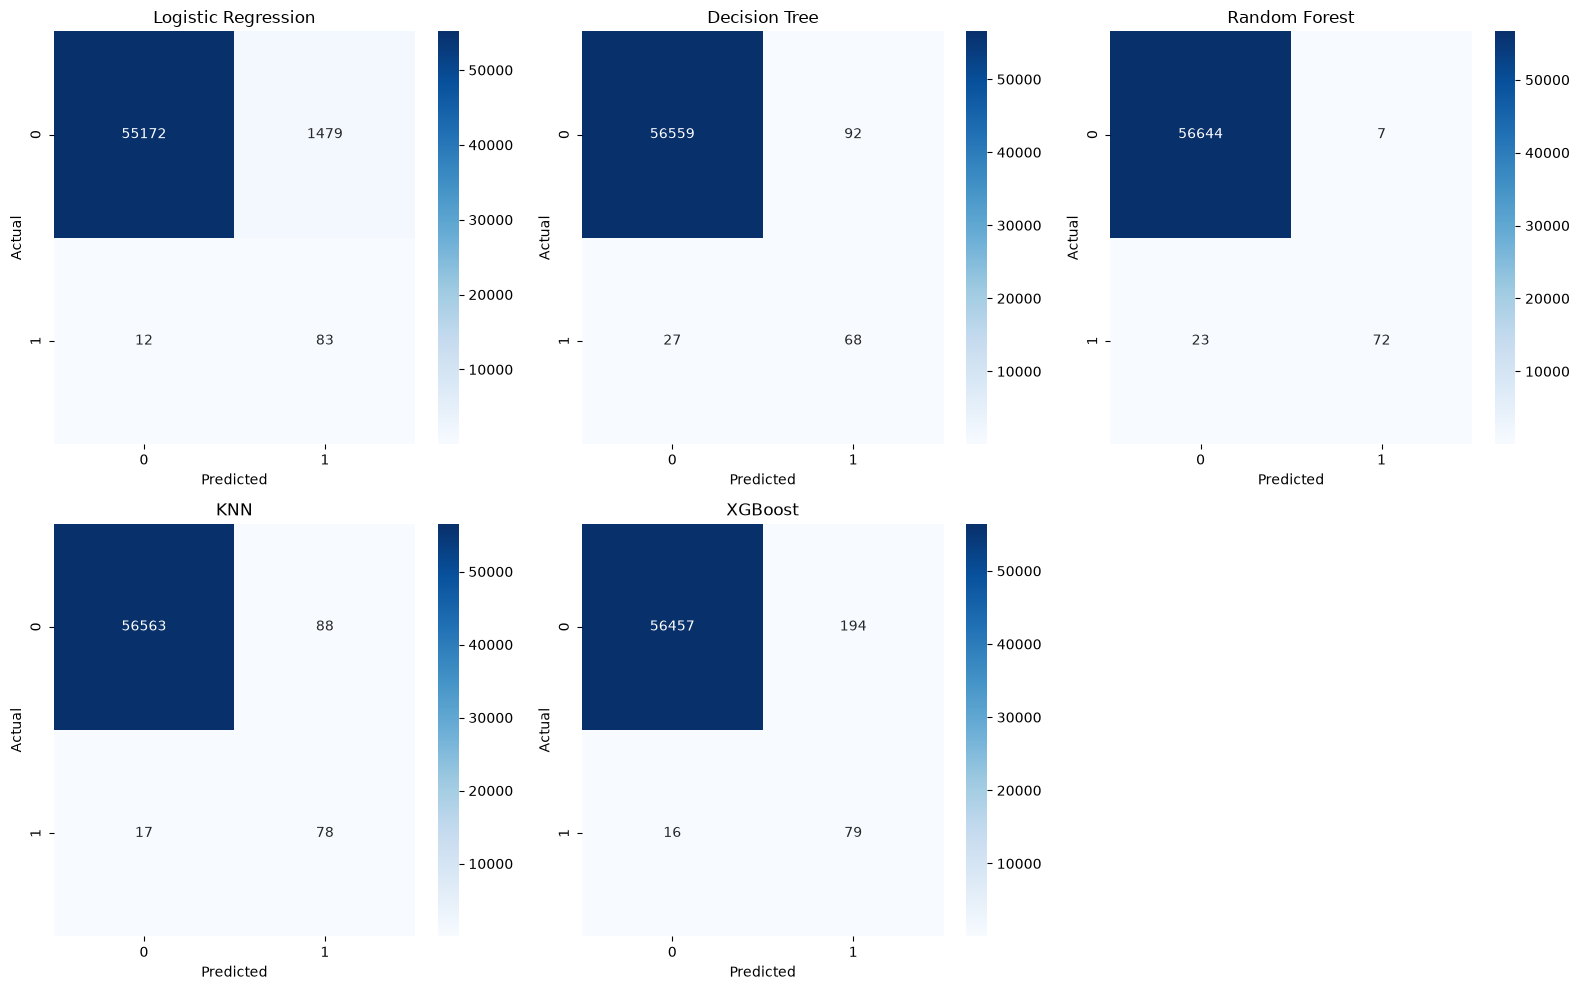

In [43]:
# Confusion Matrix for All Models

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes.flat[-1].axis('off')

plt.tight_layout()
plt.show()

#### 8.6 Model Comparison

In [44]:
# Sort Models by F1 Score

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.999471,0.911392,0.757895,0.827586,0.954320
1,KNN,0.998150,0.469880,0.821053,0.597701,0.909967
2,Decision Tree,0.997903,0.425000,0.715789,0.533333,0.857083
3,XGBoost,0.996299,0.289377,0.831579,0.429348,0.976251
4,Logistic Regression,0.973725,0.053137,0.873684,0.100181,0.961850


#### 8.7 Performance Visualization

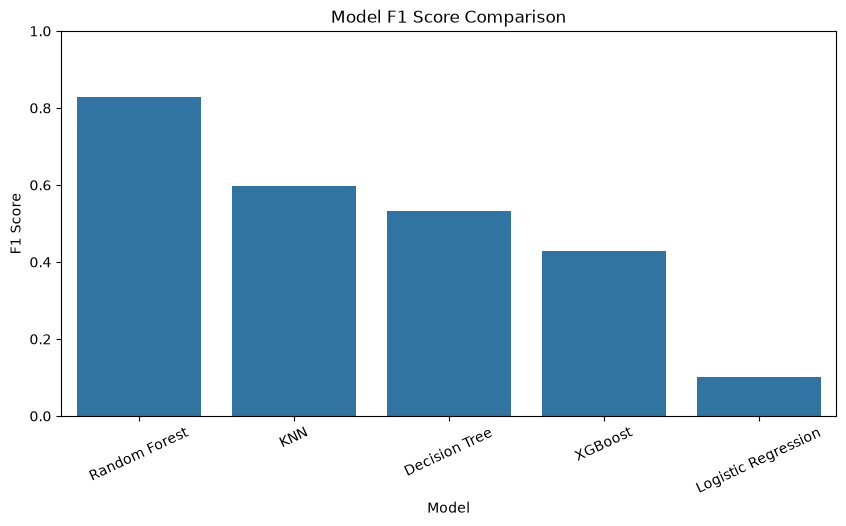

In [45]:
# Compare Model Performance

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Model F1 Score Comparison")
plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.show()

#### 8.8 Save Results

In [61]:
import os

os.makedirs("../reports", exist_ok=True)

results_df.to_csv(
    "../reports/model_performance.csv",
    index=False
)

print("Model Performance Saved Successfully!")

Model Performance Saved Successfully!


### Step 9 – Model Optimization

#### 9.1 Select Best Model

In [46]:
# Select Best Model Based on F1 Score

best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]["F1 Score"])

Best Model: Random Forest
Best F1 Score: 0.8275862068965517


#### 9.2 Hyperparameter Tuning
- We will use RandomizedSearchCV to find better Random Forest parameters.

In [48]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Parameter Grid
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt']
}

# Initialize Model
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=4,
    scoring='f1',
    cv=2,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Fit Search
random_search.fit(X_train_smote, y_train_smote)

print("Hyperparameter Tuning Completed!")

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Hyperparameter Tuning Completed!


#### 9.3 Best Parameters

In [49]:
# Display Best Parameters

print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}


#### 9.4 Optimized Model

In [50]:
# Get Optimized Model

best_rf_model = random_search.best_estimator_

print("Optimized Random Forest Model Created!")

Optimized Random Forest Model Created!


#### 9.5 Optimized Predictions

In [51]:
# Predict Test Data

y_pred_optimized = best_rf_model.predict(X_test)

y_prob_optimized = best_rf_model.predict_proba(X_test)[:, 1]

print("Optimized Predictions Completed!")

Optimized Predictions Completed!


#### 9.6 Optimized Evaluation

In [52]:
# Evaluate Optimized Model

print("Accuracy:", accuracy_score(y_test, y_pred_optimized))

print("Precision:", precision_score(y_test, y_pred_optimized))

print("Recall:", recall_score(y_test, y_pred_optimized))

print("F1 Score:", f1_score(y_test, y_pred_optimized))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_optimized))

Accuracy: 0.9992069925633524
Precision: 0.7551020408163265
Recall: 0.7789473684210526
F1 Score: 0.7668393782383419
ROC-AUC: 0.964364079604671


#### 9.7 Final Comparison

In [53]:
# Compare Original and Optimized Random Forest

original_rf = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Original": [
        original_rf["Accuracy"],
        original_rf["Precision"],
        original_rf["Recall"],
        original_rf["F1 Score"],
        original_rf["ROC-AUC"]
    ], 
    "Optimized": [
        accuracy_score(y_test, y_pred_optimized),
        precision_score(y_test, y_pred_optimized),
        recall_score(y_test, y_pred_optimized),
        f1_score(y_test, y_pred_optimized),
        roc_auc_score(y_test, y_prob_optimized)
    ]
})

comparison

,Metric,Original,Optimized
0,Accuracy,0.999471,0.999207
1,Precision,0.911392,0.755102
2,Recall,0.757895,0.778947
3,F1 Score,0.827586,0.766839
4,ROC-AUC,0.954320,0.964364


### Step 11 – Model Saving

#### 10.1 Import Joblib

In [54]:
import joblib
import os

print("Joblib Imported Successfully!")

Joblib Imported Successfully!


#### 10.2 Create Directory

In [55]:
# Create Models Directory
os.makedirs("../models", exist_ok=True)

print("Models Directory Created!")

Models Directory Created!


#### 10.3 Save Model

In [56]:
# Save Optimized Random Forest Model
joblib.dump(best_rf_model, "../models/fraud_detection_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


#### 10.4 Save Scaler

In [57]:
# Save Standard Scaler
joblib.dump(scaler, "../models/scaler.pkl")

print("Scaler Saved Successfully!")

Scaler Saved Successfully!


#### 10.5 Verify Files

In [58]:
# Check Saved Model Files
print("Saved Files:")

for file in os.listdir("../models"):
    print(file)

Saved Files:
fraud_detection_model.pkl
scaler.pkl


#### 10.6 Load Model

In [59]:
# Load Saved Model and Scaler
loaded_model = joblib.load("../models/fraud_detection_model.pkl")
loaded_scaler = joblib.load("../models/scaler.pkl")

print("Model Loaded Successfully!")
print("Scaler Loaded Successfully!")

Model Loaded Successfully!
Scaler Loaded Successfully!


#### 10.7 Test Model

In [60]:
# Test Loaded Model
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Sample Predictions:", sample_prediction)

Sample Predictions: [0 0 0 0 0]
